# Port of Rotterdam – Ship Travel Time Prediction

End-to-end ML pipeline: feature engineering, weather-data enrichment, model training (Linear Regression, Decision Tree, CatBoost), evaluation (MAE, RMSE, R², 5-fold CV), feature importance and bias analysis per ship type.

*The training data is confidential (provided by Port of Rotterdam) and is not included in this repository.*

In [ ]:
!pip install pandas scikit-learn

In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import cross_val_score


In [3]:
df = pd.read_csv("trainingsset.csv")

In [4]:
df['diepgang_meter'] = df['diepgang'] / 100
df['lengte_meter'] = df['lengte'] / 100
df['datumtijd'] = pd.to_datetime(df['datumtijd'])
df['uur'] = df['datumtijd'].dt.hour
df['maand'] = df['datumtijd'].dt.month
df['dag_van_week'] = df['datumtijd'].dt.dayofweek

In [5]:
for kolom in ['reistijd_a', 'reistijd_b', 'reistijd_c']:
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)
    IQR = Q3 - Q1
    df = df[(df[kolom] >= Q1 - 1.5 * IQR) & (df[kolom] <= Q3 + 1.5 * IQR)]

In [6]:
vaarafstand_b = {'Vulcaanhaven': 31.0, 'Waalhaven': 35.9, 'Amaliahaven': 17.0, 
                 'Brittanniëhaven': 22.1, 'Amazonehaven': 12.2, 
                 '3e Petroleumhaven': 26.8, '7e Petroleumhaven': 18.5, 
                 'Beneluxhaven': 12.9}
vaarafstand_c = {'Vulcaanhaven': 1.96, 'Waalhaven': 2.43, 'Amaliahaven': 3.75, 
                 'Brittanniëhaven': 2.57, 'Amazonehaven': 2.26, 
                 '3e Petroleumhaven': 2.77, '7e Petroleumhaven': 2.24, 
                 'Beneluxhaven': 1.91}
df['vaarafstand_a'] = 20.8
df['vaarafstand_b'] = df['havenbekken'].map(vaarafstand_b)
df['vaarafstand_c'] = df['havenbekken'].map(vaarafstand_c)

In [7]:
df_weather = pd.read_csv("weather.txt", skipinitialspace=True)
df_weather.columns = df_weather.columns.str.strip()  #spaties weghalen
df_weather['YYYYMMDD'] = pd.to_datetime(df_weather['YYYYMMDD'], format='%Y%m%d') #naar datetime
df['datum'] = pd.to_datetime(df['datumtijd'].dt.date)
df = df.merge(df_weather[['YYYYMMDD', 'FG', 'TG', 'RH', 'FXX']], 
              left_on='datum', right_on='YYYYMMDD', how='left')
df[['FG', 'TG', 'RH', 'FXX']] = df[['FG', 'TG', 'RH', 'FXX']].fillna(df[['FG', 'TG', 'RH', 'FXX']].median()) #missende waarden invullen met het mediaan, 
                                                                                                              #zouden we veel waarden moeten verwijderen

In [8]:
df_model = pd.get_dummies(df, columns=['havenbekken', 'type', 'snelheidsklasse', 'direct_zwaaien'], drop_first=True)

In [9]:
features = [
    'diepgang', 'lengte', 'drukte_zeevaart', 'drukte_binnenvaart',
    'diepgang_meter', 'lengte_meter', 'uur', 'maand', 'dag_van_week',
    'aantal_slepers', 'vaarafstand_a', 'vaarafstand_b', 'vaarafstand_c',
    'havenbekken_Amazonehaven', 'havenbekken_Beneluxhaven', 
    'havenbekken_Brittanniëhaven', 'havenbekken_Vulcaanhaven', 
    'havenbekken_Waalhaven',
    'type_Combi', 'type_Dredging', 'type_General cargo', 'type_LNG', 
    'type_Navy', 'type_Offshore', 'type_Passenger', 'type_Pontoon', 
    'type_Tanker', 'type_Tug', 'type_Workship',
    'snelheidsklasse_II', 'snelheidsklasse_III', 'direct_zwaaien_zwaaien','FG', 'FXX'
]

In [10]:
X = df_model[features]
y = df_model['reistijd_totaal']

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

In [12]:
model_lr = LinearRegression()

In [13]:
model_lr.fit(X_train, y_train)
y_pred_lr = model_lr.predict(X_test)
mae_lr = mean_absolute_error(y_test, y_pred_lr)

In [14]:
mae_lr

17.159792692564103

In [15]:
scores = cross_val_score(model_lr, X, y, cv=5, scoring='neg_mean_absolute_error')
mae_cv = -scores.mean()

In [16]:
mae_cv

np.float64(17.20272933770405)

In [17]:
features

['diepgang',
 'lengte',
 'drukte_zeevaart',
 'drukte_binnenvaart',
 'diepgang_meter',
 'lengte_meter',
 'uur',
 'maand',
 'dag_van_week',
 'aantal_slepers',
 'vaarafstand_a',
 'vaarafstand_b',
 'vaarafstand_c',
 'havenbekken_Amazonehaven',
 'havenbekken_Beneluxhaven',
 'havenbekken_Brittanniëhaven',
 'havenbekken_Vulcaanhaven',
 'havenbekken_Waalhaven',
 'type_Combi',
 'type_Dredging',
 'type_General cargo',
 'type_LNG',
 'type_Navy',
 'type_Offshore',
 'type_Passenger',
 'type_Pontoon',
 'type_Tanker',
 'type_Tug',
 'type_Workship',
 'snelheidsklasse_II',
 'snelheidsklasse_III',
 'direct_zwaaien_zwaaien',
 'FG',
 'FXX']

In [ ]:
!pip install catboost

In [19]:
from catboost import CatBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [20]:
model_dt = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=20,  
    random_state=42
)

In [21]:
model_dt.fit(X_train, y_train)
y_pred_dt = model_dt.predict(X_test)

In [22]:
model_cb = CatBoostRegressor(
    iterations=500,
    depth=6,               
    learning_rate=0.05,
    random_seed=42,
    verbose=0              
)

In [23]:
model_cb.fit(X_train, y_train)
y_pred_cb = model_cb.predict(X_test)

In [24]:
def model_vergelijken(naam, y_test, y_pred):
    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2   = r2_score(y_test, y_pred)
    print(naam)
    print(f"  MAE : {mae:.2f} minuten")
    print(f"  RMSE: {rmse:.2f} minuten")
    print(f"  R²  : {r2:.4f}")

In [25]:
model_vergelijken("Linear Regression",y_test, y_pred_lr)
model_vergelijken("Decision Tree",y_test, y_pred_dt)
model_vergelijken("CatBoost",y_test, y_pred_cb)

Linear Regression
  MAE : 17.16 minuten
  RMSE: 21.51 minuten
  R²  : 0.6779
Decision Tree
  MAE : 18.43 minuten
  RMSE: 23.11 minuten
  R²  : 0.6282
CatBoost
  MAE : 17.21 minuten
  RMSE: 21.53 minuten
  R²  : 0.6775


FEATURE IMPORTANCE

In [26]:
import matplotlib.pyplot as plt

In [27]:
importances_cb = pd.Series(
    model_cb.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

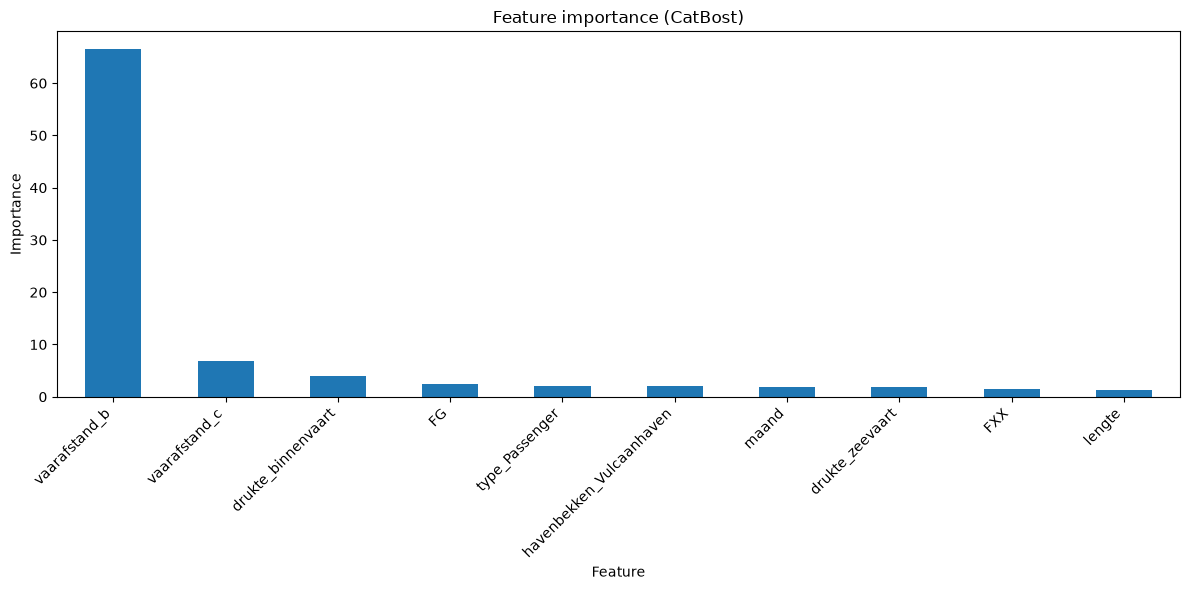

In [28]:
plt.figure(figsize=(12, 6))
importances_cb.head(10).plot(kind='bar')
plt.title('Feature importance (CatBost)')
plt.ylabel('Importance')
plt.xlabel('Feature')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [29]:
importances_dt = pd.Series(
    model_dt.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

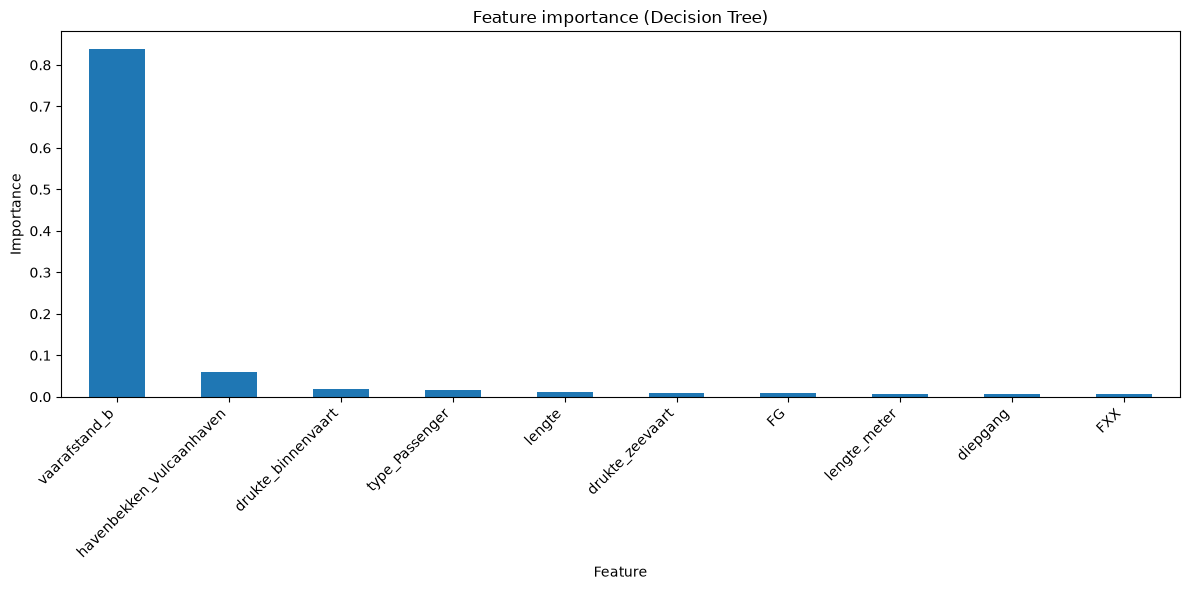

In [30]:
plt.figure(figsize=(12, 6))
importances_dt.head(10).plot(kind='bar')
plt.title('Feature importance (Decision Tree)')
plt.ylabel('Importance')
plt.xlabel('Feature')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [31]:
coef_lr = pd.Series(
    np.abs(model_lr.coef_),
    index=X_train.columns
).sort_values(ascending=False)

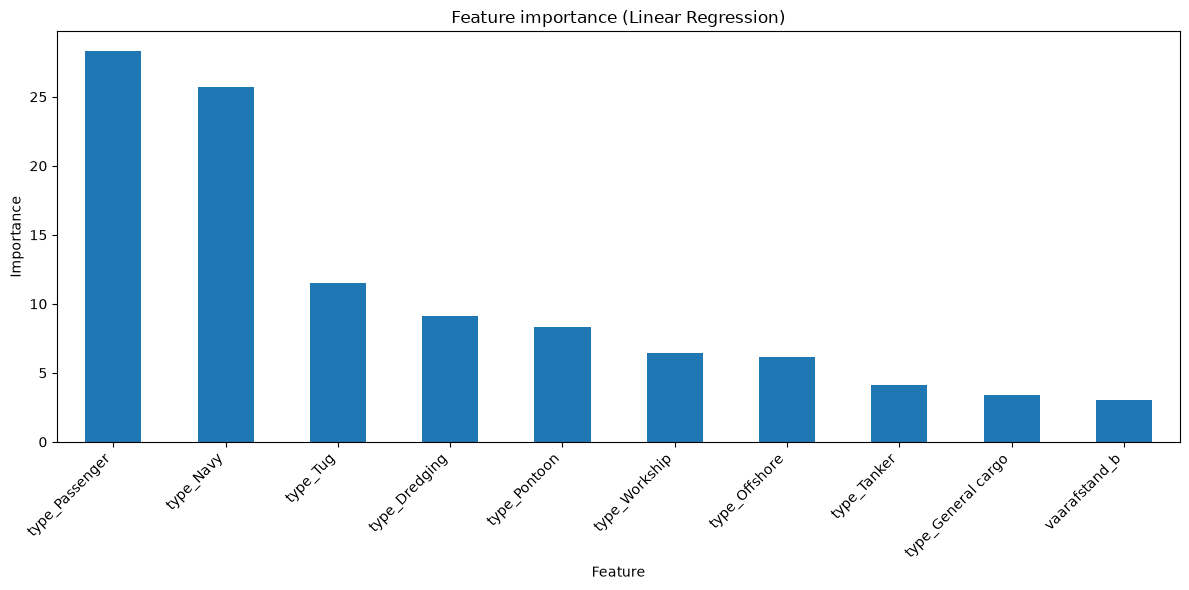

In [32]:
plt.figure(figsize=(12, 6))
coef_lr.head(10).plot(kind='bar')
plt.title('Feature importance (Linear Regression)')
plt.ylabel('Importance')
plt.xlabel('Feature')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

REPRESENTATIE 

In [33]:
type_counts = df['type'].value_counts()
type_counts

type
General cargo    11117
Tanker            5222
Passenger          374
Bulk               145
Offshore            98
Tug                 32
LNG                 19
Pontoon             13
Dredging            12
Combi                9
Navy                 4
Workship             4
Name: count, dtype: int64

Duidelijke representatiebias in het type van schip

In [34]:
types = df['type'].values[y_test.index]
fouten = abs(y_test.values - y_pred_lr)

In [35]:
mae_pertype = pd.Series(fouten, index=types).groupby(types).mean().sort_values()

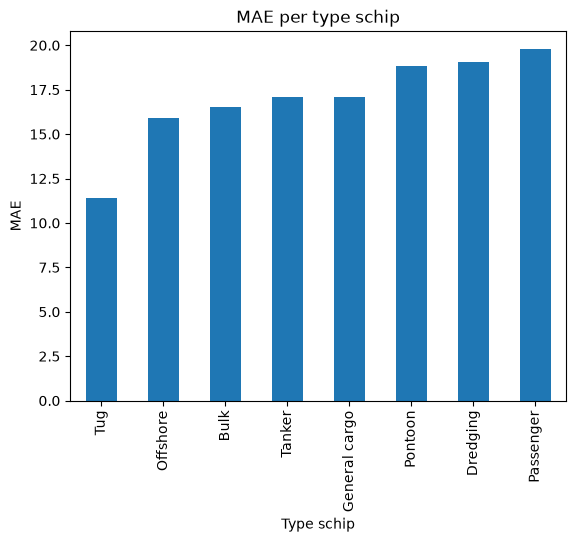

In [36]:
mae_pertype.plot(kind='bar')
plt.ylabel('MAE')
plt.xlabel('Type schip')
plt.title('MAE per type schip')
plt.show()

Sommige types schepen missen in de visualisatie want ze komen zo weinig voor dat deze niet terechkwamen tijdens de test train split

CatBoost Model gebruikt zonder encoding om de echte potentiel te bekijken

In [38]:
features_cb = [
    'diepgang', 'lengte', 'drukte_zeevaart', 'drukte_binnenvaart',
    'uur', 'maand', 'dag_van_week', 'aantal_slepers',
    'vaarafstand_a', 'vaarafstand_b', 'vaarafstand_c',
    'FG', 'FXX',
    'havenbekken', 'type', 'snelheidsklasse', 'direct_zwaaien'
]

cat_features = ['havenbekken', 'type', 'snelheidsklasse', 'direct_zwaaien']

X_cb = df[features_cb]
y_cb = df['reistijd_totaal']

X_train_cb, X_test_cb, y_train_cb, y_test_cb = train_test_split(
    X_cb, y_cb, test_size=0.1, random_state=42
)

model_cb2 = CatBoostRegressor(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    random_seed=42,
    verbose=0
)

model_cb2.fit(X_train_cb, y_train_cb, cat_features=cat_features)
y_pred_cb2 = model_cb2.predict(X_test_cb)

mae_cb2 = mean_absolute_error(y_test_cb, y_pred_cb2)

In [39]:
mae_cb2

17.179426389820108